**A simple fuzzy dating preference experiment by Care Achieng**

I adapted the tipping tutorial to experiment with one idea from Mixed Signals: how the importance of a drinking preference changes the treatment of a partial match.

I use closeness and importance, both rated from 0 to 10. The output is a preference fit score from 0 to 100. A high score means this single preference gives little reason to lower a profile's ranking.

For example, drinking on special occasions versus drinking socially at weekends could be assigned closeness 7/10.

In [8]:
%pip install scikit-fuzzy==0.5.0 numpy matplotlib scipy


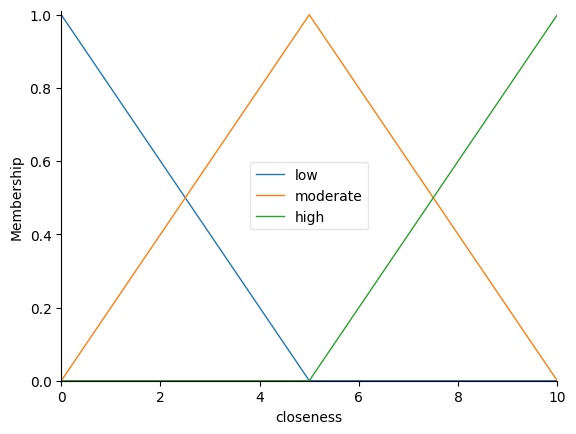

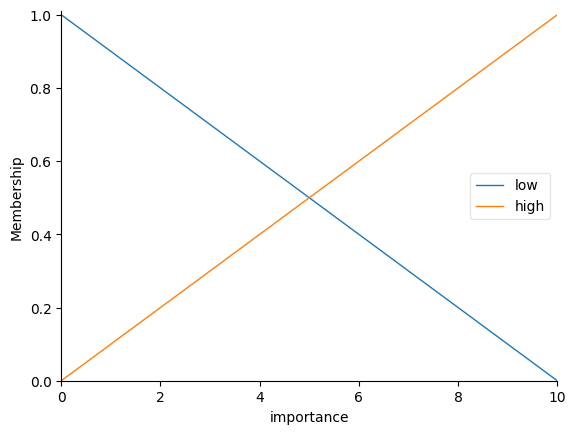

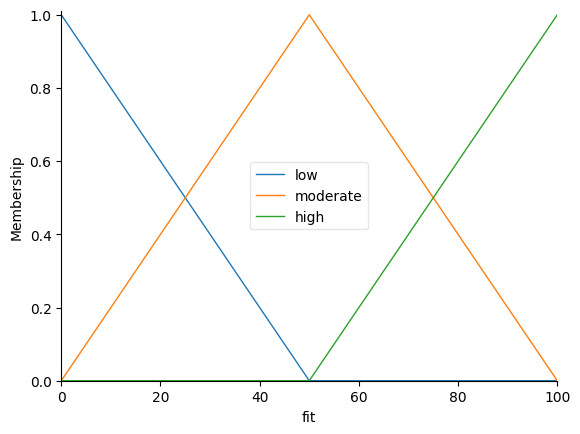

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

closeness = ctrl.Antecedent(np.arange(0, 11, 1), 'closeness')
importance = ctrl.Antecedent(np.arange(0, 11, 1), 'importance')
fit = ctrl.Consequent(np.arange(0, 101, 1), 'fit')

closeness.automf(3, names=['low', 'moderate', 'high'])
# Only two importance sets are needed for this small experiment.
importance['low'] = fuzz.trimf(importance.universe, [0, 0, 10])
importance['high'] = fuzz.trimf(importance.universe, [0, 10, 10])

fit['low'] = fuzz.trimf(fit.universe, [0, 0, 50])
fit['moderate'] = fuzz.trimf(fit.universe, [0, 50, 100])
fit['high'] = fuzz.trimf(fit.universe, [50, 100, 100])

closeness.view()
importance.view()
fit.view()
plt.show()


**My rules**

1. If closeness is high, fit is high.
2. If closeness is low AND importance is high, fit is low.
3. If closeness is moderate AND importance is high, fit is moderate.
4. If importance is low, fit is high.

Rule 4 means that an unimportant preference should not count strongly against a profile.

AND uses minimum; fired outputs are aggregated using maximum and converted to a number using centroid defuzzification.

In [13]:
rule1 = ctrl.Rule(closeness['high'], fit['high'])
rule2 = ctrl.Rule(closeness['low'] & importance['high'], fit['low'])
rule3 = ctrl.Rule(closeness['moderate'] & importance['high'], fit['moderate'])
rule4 = ctrl.Rule(importance['low'], fit['high'])

preference_ctrl = ctrl.ControlSystem([rule1, rule2, rule3, rule4])

def calculate_fit(closeness_value, importance_value):
    simulation = ctrl.ControlSystemSimulation(preference_ctrl)
    simulation.input['closeness'] = closeness_value
    simulation.input['importance'] = importance_value
    simulation.compute()
    return simulation

**Experiment: keeping closeness fixed and changing importance**

I hold closeness at 7/10, representing a partial drinking-preference match.

I compare low importance (2/10) with high importance (8/10).

I also try closeness 2/10 to see what happens with a larger mismatch.

Partial match, low importance: closeness=7, importance=2, fit=67.25
Partial match, high importance: closeness=7, importance=8, fit=53.77
Distant match, low importance: closeness=2, importance=2, fit=65.43
Distant match, high importance: closeness=2, importance=8, fit=42.54


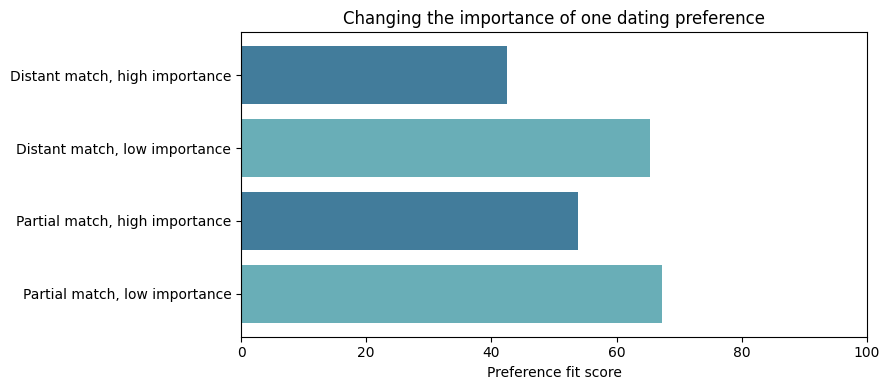

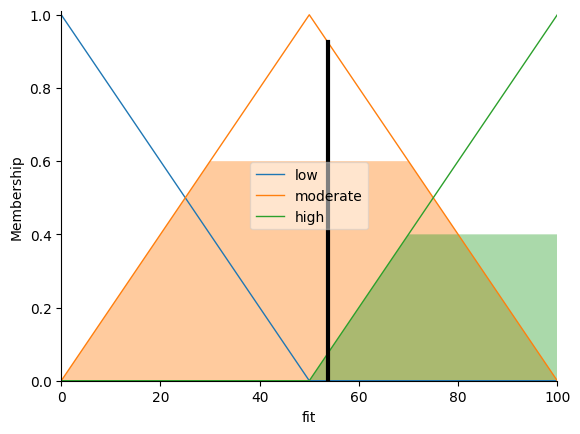

In [15]:
experiments = [
    ('Partial match, low importance', 7, 2),
    ('Partial match, high importance', 7, 8),
    ('Distant match, low importance', 2, 2),
    ('Distant match, high importance', 2, 8),
]
scores = []
for label, close_value, important_value in experiments:
    simulation = calculate_fit(close_value, important_value)
    score = simulation.output['fit']
    scores.append(score)
    print(f'{label}: closeness={close_value}, importance={important_value}, fit={score:.2f}')

plt.figure(figsize=(9, 4))
plt.barh([e[0] for e in experiments], scores, color=['#69aeb7', '#427c9b', '#69aeb7', '#427c9b'])
plt.xlabel('Preference fit score')
plt.xlim(0, 100)
plt.title('Changing the importance of one dating preference')
plt.tight_layout()
plt.show()

# View the aggregated fuzzy output for the partial match with high importance.
simulation = calculate_fit(7, 8)
fit.view(sim=simulation)
plt.show()


**Observations**

The partial match receives a lower fit score when importance increases.

The larger mismatch also scores lower when the preference matters more.

This follows the rules: low importance activates the high-fit output, while high importance allows a mismatch to activate moderate or low fit.

Changing closeness from 7 to 2

Partial match, low importance: closeness=2, importance=2, fit=65.43
Partial match, high importance: closeness=2, importance=8, fit=42.54
Distant match, low importance: closeness=7, importance=2, fit=67.25
Distant match, high importance: closeness=7, importance=8, fit=53.77


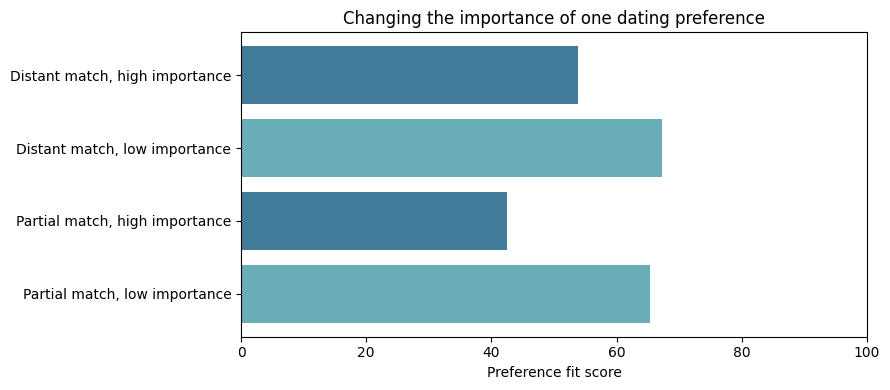

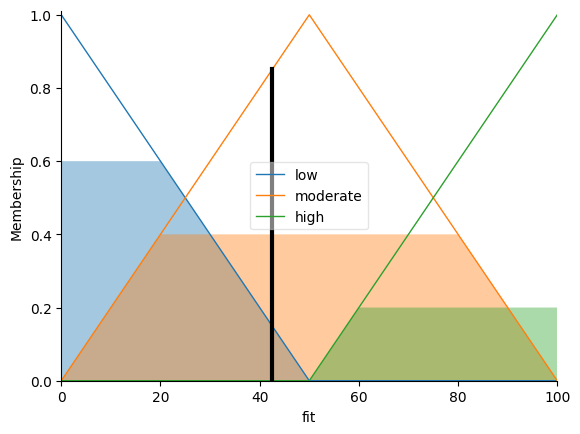

In [23]:
experiments = [
    ('Partial match, low importance', 2, 2),
    ('Partial match, high importance', 2, 8),
    ('Distant match, low importance', 7, 2),
    ('Distant match, high importance', 7, 8),
]
scores = []
for label, close_value, important_value in experiments:
    simulation = calculate_fit(close_value, important_value)
    score = simulation.output['fit']
    scores.append(score)
    print(f'{label}: closeness={close_value}, importance={important_value}, fit={score:.2f}')

plt.figure(figsize=(9, 4))
plt.barh([e[0] for e in experiments], scores, color=['#69aeb7', '#427c9b', '#69aeb7', '#427c9b'])
plt.xlabel('Preference fit score')
plt.xlim(0, 100)
plt.title('Changing the importance of one dating preference')
plt.tight_layout()
plt.show()

# View the aggregated fuzzy output for the partial match with high importance.
simulation = calculate_fit(2, 8)
fit.view(sim=simulation)
plt.show()